1: Introduction

In [1]:
# Day 34: Linear Regression Introduction
# Objective:
# Build a simple Linear Regression model.
# Linear Regression predicts numerical values using input features.
# It finds the best-fit straight line between input and target.

print("Day 34 - Linear Regression Introduction")
print("Building a Simple Machine Learning Model")

Day 34 - Linear Regression Introduction
Building a Simple Machine Learning Model


2: Import Libraries

In [2]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("All libraries imported successfully!")

All libraries imported successfully!


3: Load Dataset

In [3]:
# Load the Diabetes dataset from Scikit-learn
# We will predict a numerical target using BMI as one input feature.

diabetes = load_diabetes()

df = pd.DataFrame(
    diabetes.data,
    columns=diabetes.feature_names
)

df["Target"] = diabetes.target

print("Dataset loaded successfully!")
display(df.head())

Dataset loaded successfully!


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,Target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


4: Explore Dataset

In [4]:
# Explore the dataset structure and statistical information

print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (442, 11)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
 10  Target  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB

Statistical Summary:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,Target
count,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,442.000000
mean,-2.511817e-19,1.230790e-17,-2.245564e-16,-4.797570e-17,-1.381499e-17,3.918434e-17,-5.777179e-18,-9.042540e-18,9.293722e-17,1.130318e-17,152.133484
std,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,77.093005
min,-1.072256e-01,-4.464164e-02,-9.027530e-02,-1.123988e-01,-1.267807e-01,-1.156131e-01,-1.023071e-01,-7.639450e-02,-1.260971e-01,-1.377672e-01,25.000000
25%,-3.729927e-02,-4.464164e-02,-3.422907e-02,-3.665608e-02,-3.424784e-02,-3.035840e-02,-3.511716e-02,-3.949338e-02,-3.324559e-02,-3.317903e-02,87.000000
50%,5.383060e-03,-4.464164e-02,-7.283766e-03,-5.670422e-03,-4.320866e-03,-3.819065e-03,-6.584468e-03,-2.592262e-03,-1.947171e-03,-1.077698e-03,140.500000
75%,3.807591e-02,5.068012e-02,3.124802e-02,3.564379e-02,2.835801e-02,2.984439e-02,2.931150e-02,3.430886e-02,3.243232e-02,2.791705e-02,211.500000
max,1.107267e-01,5.068012e-02,1.705552e-01,1.320436e-01,1.539137e-01,1.987880e-01,1.811791e-01,1.852344e-01,1.335973e-01,1.356118e-01,346.000000



Missing Values:
age       0
sex       0
bmi       0
bp        0
s1        0
s2        0
s3        0
s4        0
s5        0
s6        0
Target    0
dtype: int64


5: Select Feature and Target

In [5]:
# Select BMI as the input feature (X)
# Select Target as the output variable (y)

X = df[["bmi"]]
y = df["Target"]

print("Input Feature:")
display(X.head())

print("\nTarget Variable:")
print(y.head())

Input Feature:


,bmi
0,0.061696
1,-0.051474
2,0.044451
3,-0.011595
4,-0.036385



Target Variable:
0    151.0
1     75.0
2    141.0
3    206.0
4    135.0
Name: Target, dtype: float64


6: Split Dataset

In [6]:
# Divide data into 80% training and 20% testing sets.
# Training data teaches the model.
# Testing data checks predictions on unseen data.

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

Training Data Shape: (353, 1)
Testing Data Shape: (89, 1)


7: Create and Train Model

In [7]:
# Create a Linear Regression model
# fit() trains the model using training data.

model = LinearRegression()

model.fit(X_train, y_train)

print("Linear Regression Model Trained Successfully!")

Linear Regression Model Trained Successfully!


8: Display Model Parameters

In [8]:
# Coefficient represents the slope of the regression line.
# Intercept represents the value when input feature is zero.

print("Model Coefficient:", model.coef_[0])
print("Model Intercept:", model.intercept_)

Model Coefficient: 998.5776891375598
Model Intercept: 152.00335421448167


9: Make Predictions

In [9]:
# Predict target values using unseen testing data.

y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Actual Values": y_test.values,
    "Predicted Values": y_pred
})

print("Prediction Results:")
display(results.head(10))

Prediction Results:


,Actual Values,Predicted Values
0,219.0,145.806227
1,70.0,188.857390
2,202.0,147.958785
3,230.0,203.925298
4,111.0,131.814599
5,84.0,127.509482
6,242.0,322.315998
7,272.0,197.467623
8,94.0,61.856458
9,96.0,167.331809


10: Visualize Regression Line

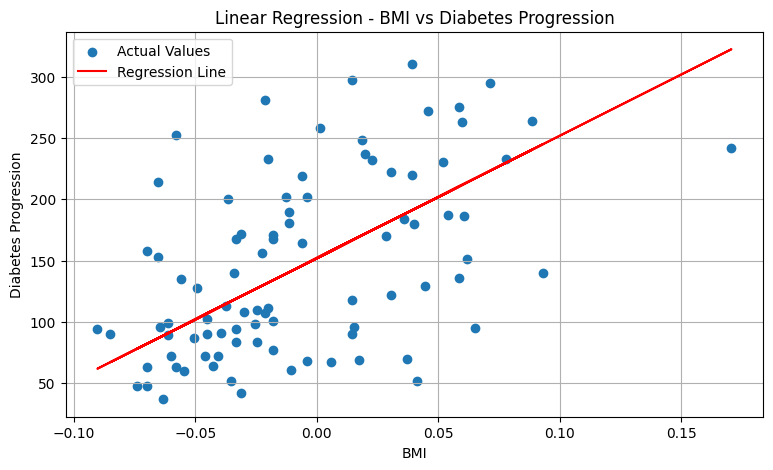

In [10]:
# Scatter plot shows actual data points.
# Regression line shows the relationship learned by the model.

plt.figure(figsize=(9, 5))

plt.scatter(X_test["bmi"], y_test, label="Actual Values")
plt.plot(
    X_test["bmi"],
    y_pred,
    color="red",
    label="Regression Line"
)

plt.title("Linear Regression - BMI vs Diabetes Progression")
plt.xlabel("BMI")
plt.ylabel("Diabetes Progression")
plt.legend()
plt.grid(True)
plt.show()

11: Evaluate Model

In [11]:
# Evaluate the model using common regression metrics.
# MAE: Average absolute prediction error.
# MSE: Average squared prediction error.
# RMSE: Square root of MSE.
# R2: Indicates how much variation is explained by the model.

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MODEL EVALUATION")
print("----------------------")
print("Mean Absolute Error:", mae)
print("Mean Squared Error:", mse)
print("Root Mean Squared Error:", rmse)
print("R2 Score:", r2)

MODEL EVALUATION
----------------------
Mean Absolute Error: 52.259976445345536
Mean Squared Error: 4061.8259284949268
Root Mean Squared Error: 63.73245584860925
R2 Score: 0.23335039815872138


12: Actual vs Predicted Visualization

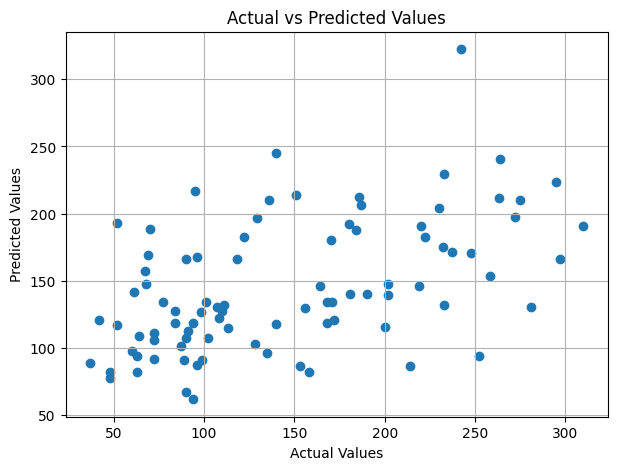

In [12]:
# Compare actual target values with predicted values.

plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_pred)
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs Predicted Values")

plt.grid(True)
plt.show()